# 08 — 5-Fold Cross-Validation: does the Phase 6 comparison hold across splits?

Phase 6 compared models on a **single** 80/20 engine-level split. Every
model in that comparison was trained on the same 80 engines, so the ranking
(RSF ahead on NASA score and concordance) could in principle depend on
which 20 engines happened to be held out. This
notebook checks whether those conclusions are stable across different
splits, or an artifact of which 20 engines happened to land in the holdout.

**Evaluation design, and why it isn't just "hold out some rows":** every
training engine runs to failure, so a held-out engine's last row always has
RUL=0 by construction — evaluating there would be degenerate, and nothing
like the real test set. Instead, each held-out engine in a fold is given a
single random truncation point (30-90% of its observed lifetime) -- the
same *structure* as NASA's test set, though not the same distribution of
truncation points and scored against its true
remaining life from that point — see `src/turbofan_rul/cross_validation.py`
for the implementation and `tests/test_cross_validation.py` for what's
checked about it (truncation points are in-bounds, reproducible, never
degenerate).

**Scope:** Cox PH, Weibull AFT, and RSF are cross-validated (5 folds,
`GroupKFold` on engine number so no engine's cycles ever span the
train/test boundary within a fold). The deep models from Phase 7 are not
included here — they were never deployment candidates, and each one would
add several slow refits per fold.
RSF uses `row_stride=5` rather than Phase 5's `row_stride=3`, purely for
fold-loop runtime — this notebook cares about relative stability across
folds, not squeezing out RSF's single best achievable score, which Phase 5
already reported.


In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from lifelines import WeibullAFTFitter
from lifelines.utils import concordance_index

sys.path.append(str(Path("..") / "src"))
from turbofan_rul import cross_validation, data_loading, evaluation, features, labeling, models, plotting

plotting.style()
SUBSET, CAP, DURATION_EPS = "FD001", 125, 1e-3
N_SPLITS = 5
RSF_ROW_STRIDE = 5
DATA_DIR = Path("..") / "data" / "raw"
PROCESSED_DIR = Path("..") / "data" / "processed"

In [2]:
data_loading.download_cmapss(SUBSET, data_dir=DATA_DIR)
cmapss = data_loading.load_subset(SUBSET, data_dir=DATA_DIR)
kept_sensors = features.load_kept_sensors(PROCESSED_DIR / f"{SUBSET.lower()}_sensor_selection.json")

curated_cols = ["cycle_count"]
for s in kept_sensors:
    curated_cols += [f"{s}_roll15_mean", f"{s}_roll15_slope"]

units = cmapss.train["unit_number"].unique()
gkf = GroupKFold(n_splits=N_SPLITS)
fold_splits = list(gkf.split(units, groups=units))
print(f"{N_SPLITS} folds over {len(units)} engines: "
      f"{[len(units[tr]) for tr, _ in fold_splits]} train / "
      f"{[len(units[te]) for _, te in fold_splits]} held-out per fold")

5 folds over 100 engines: [80, 80, 80, 80, 80] train / [20, 20, 20, 20, 20] held-out per fold


## Run all 5 folds

In [3]:
fold_results = []

for fold_idx, (train_pos, test_pos) in enumerate(fold_splits):
    t0 = time.time()
    train_units, test_units = units[train_pos], units[test_pos]

    fold_train_raw = cmapss.train[cmapss.train.unit_number.isin(train_units)]
    fold_test_raw = cmapss.train[cmapss.train.unit_number.isin(test_units)]

    # --- fit all three models on this fold's training engines ---
    fold_train_survival = labeling.build_train_survival_frame(fold_train_raw, cap=CAP)
    fold_train_survival = features.build_feature_matrix(fold_train_survival, kept_sensors=kept_sensors)
    META_COLS = {"unit_number", "time_cycles", "RUL", "duration", "event"}
    full_cols = [c for c in fold_train_survival.columns if c not in META_COLS]

    scaler = StandardScaler().fit(fold_train_survival[curated_cols])
    fold_train_scaled = fold_train_survival.copy()
    fold_train_scaled[curated_cols] = scaler.transform(fold_train_survival[curated_cols])

    cox_model = models.fit_cox_ph(fold_train_scaled, curated_cols, penalizer=0.1)

    aft_fit_df = fold_train_scaled.copy()
    aft_fit_df["duration"] = aft_fit_df["duration"] + DURATION_EPS
    weibull_model = WeibullAFTFitter(penalizer=0.1)
    weibull_model.fit(aft_fit_df[curated_cols + ["duration", "event"]],
                       duration_col="duration", event_col="event")

    rsf_model = models.fit_random_survival_forest(
        fold_train_survival, full_cols, row_stride=RSF_ROW_STRIDE,
        duration_eps=DURATION_EPS, random_state=42,
    )

    # --- build the truncated evaluation frame on held-out engines ---
    fold_test_featured = features.build_feature_matrix(fold_test_raw, kept_sensors=kept_sensors)
    truncation_points = cross_validation.sample_truncation_points(
        fold_test_raw, min_frac=0.3, max_frac=0.9, random_state=42
    )
    eval_frame = cross_validation.build_truncated_eval_frame(fold_test_featured, truncation_points)
    eval_scaled = eval_frame.copy()
    eval_scaled[curated_cols] = scaler.transform(eval_frame[curated_cols])
    true_rul = eval_frame["true_rul"].values

    # --- predict + score each model ---
    cox_pred = cox_model.predict_expectation(eval_scaled[curated_cols]).values
    aft_pred = weibull_model.predict_percentile(eval_scaled[curated_cols], p=0.5).values
    rsf_pred = models.predict_rul_from_survival(rsf_model, eval_frame[full_cols])["pred_rul"].values

    for model_name, pred in [("Cox PH", cox_pred), ("Weibull AFT", aft_pred), ("RSF", rsf_pred)]:
        metrics = evaluation.evaluate_rul_predictions(true_rul, pred, model_name=model_name)
        metrics["cindex"] = concordance_index(true_rul, pred, event_observed=np.ones(len(true_rul)))
        metrics["fold"] = fold_idx
        fold_results.append(metrics)

    print(f"fold {fold_idx}: {len(test_units)} held-out engines, {time.time() - t0:.1f}s")

fold_results_df = pd.DataFrame(fold_results)
fold_results_df.to_csv(PROCESSED_DIR / "cv_fold_results_fd001.csv", index=False)
print("\nAll folds complete.")

fold 0: 20 held-out engines, 37.2s


fold 1: 20 held-out engines, 34.0s


fold 2: 20 held-out engines, 33.5s


fold 3: 20 held-out engines, 30.9s


fold 4: 20 held-out engines, 30.9s

All folds complete.


## Per-fold results, and the mean/std that actually answers the question

In [4]:
display(fold_results_df[["fold", "model", "cindex", "nasa_score", "mae"]].round(3))

summary = fold_results_df.groupby("model")[["cindex", "nasa_score", "mae"]].agg(["mean", "std"])
summary.columns = ["_".join(c) for c in summary.columns]
display(summary.round(4))

,fold,model,cindex,nasa_score,mae
0,0,Cox PH,0.789,366.650,17.102
1,0,Weibull AFT,0.784,282.839,19.557
2,0,RSF,0.853,240.928,15.803
3,1,Cox PH,0.762,191.222,20.061
4,1,Weibull AFT,0.788,118.403,17.643
5,1,RSF,0.825,124.800,14.616
6,2,Cox PH,0.878,255.142,18.261
7,2,Weibull AFT,0.883,106.203,14.196
8,2,RSF,0.878,176.026,16.071
9,3,Cox PH,0.745,377.444,20.562


,cindex_mean,cindex_std,nasa_score_mean,nasa_score_std,mae_mean,mae_std
model,,,,,,
Cox PH,0.7979,0.0522,426.5740,298.6942,19.3569,1.6056
RSF,0.8497,0.0192,233.0414,189.1521,15.4547,1.4816
Weibull AFT,0.8032,0.0481,537.7540,778.8719,19.0343,3.2706


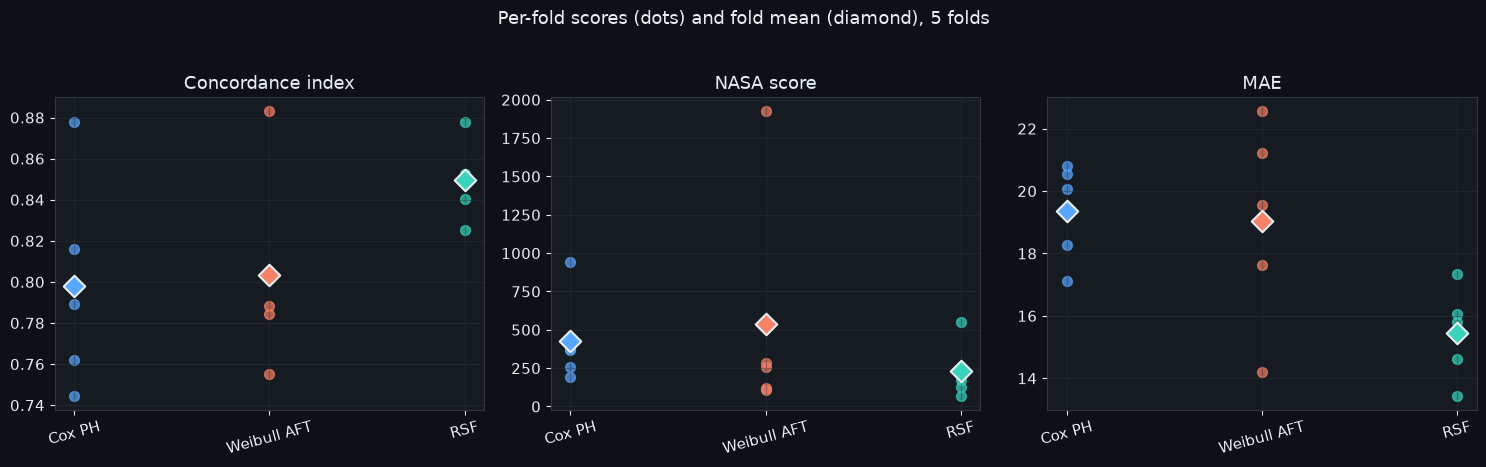

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
metrics_to_plot = ["cindex", "nasa_score", "mae"]
titles = ["Concordance index", "NASA score", "MAE"]

for ax, metric, title in zip(axes, metrics_to_plot, titles):
    for i, model_name in enumerate(fold_results_df["model"].unique()):
        vals = fold_results_df[fold_results_df.model == model_name][metric].values
        ax.scatter([i] * len(vals), vals, color=plotting.PALETTE[i], alpha=0.7, s=50)
        ax.scatter(i, vals.mean(), color=plotting.PALETTE[i], marker="D", s=120,
                   edgecolor=plotting.FG, linewidth=1.5, zorder=5)
    ax.set_xticks(range(len(fold_results_df["model"].unique())))
    ax.set_xticklabels(fold_results_df["model"].unique(), rotation=15)
    ax.set_title(title)
fig.suptitle("Per-fold scores (dots) and fold mean (diamond), 5 folds", y=1.03)
plt.tight_layout()
plt.show()

## Does the Phase 6 ranking survive?

The CV concordance here is **engine-level** C on point predictions (one row
per held-out engine), so it's compared with Phase 6's `test_cindex` -- the
same quantity on the official test set -- not with the row-level
validation C (0.901 etc.) from notebooks 03-05, which measures something
different.

In [6]:
phase6_results = pd.read_csv(PROCESSED_DIR / "model_comparison_fd001.csv", index_col="model")
phase6_results = phase6_results.rename(index={"Random Survival Forest": "RSF"})
phase6_single_split = pd.DataFrame({
    "phase6_test_cindex": phase6_results["test_cindex"],
    "phase6_nasa_score_mean": phase6_results["nasa_score"] / 100,  # 100 official test engines
})

cv_means = fold_results_df.groupby("model")[["cindex", "nasa_score_mean"]].mean()
cv_stds = fold_results_df.groupby("model")[["cindex", "nasa_score_mean"]].std()

comparison = phase6_single_split.join(cv_means.rename(
    columns={"cindex": "cv_cindex_mean", "nasa_score_mean": "cv_nasa_mean"}
)).join(cv_stds.rename(
    columns={"cindex": "cv_cindex_std", "nasa_score_mean": "cv_nasa_std"}
))
display(comparison.round(4))

by_fold = fold_results_df.pivot(index="fold", columns="model", values="cindex")
others = by_fold.drop(columns="RSF").max(axis=1)
rsf_strict_wins = int((by_fold["RSF"] > others + 1e-9).sum())
rsf_ties = int((abs(by_fold["RSF"] - others) <= 1e-9).sum())
print(f"\nRSF has the strictly best concordance in {rsf_strict_wins}/{N_SPLITS} folds"
      f" (ties for best in {rsf_ties}).")
nasa_by_fold = fold_results_df.pivot(index="fold", columns="model", values="nasa_score")
rsf_nasa_wins = int((nasa_by_fold["RSF"] < nasa_by_fold.drop(columns="RSF").min(axis=1)).sum())
print(f"RSF has the best (lowest) NASA score in {rsf_nasa_wins}/{N_SPLITS} folds.")
display(by_fold.round(3))

,phase6_test_cindex,phase6_nasa_score_mean,cv_cindex_mean,cv_nasa_mean,cv_cindex_std,cv_nasa_std
model,,,,,,
Cox PH,0.821,16.7250,0.7979,21.3287,0.0522,14.9347
Weibull AFT,0.818,12.8820,0.8032,26.8877,0.0481,38.9436
RSF,0.864,4.6254,0.8497,11.6521,0.0192,9.4576



RSF has the strictly best concordance in 4/5 folds (ties for best in 0).
RSF has the best (lowest) NASA score in 3/5 folds.


model,Cox PH,RSF,Weibull AFT
fold,,,
0,0.789,0.853,0.784
1,0.762,0.825,0.788
2,0.878,0.878,0.883
3,0.745,0.840,0.755
4,0.816,0.853,0.805


## Verdict

Two different questions, answered separately rather than conflated:

**Does the RSF-leads ranking hold?** Yes, on both metrics, with the details
stated plainly:
- **Concordance:** RSF has the strictly best C in 4 of 5 folds. In the
  other fold (fold 2) Weibull is best (0.883) and RSF ties Cox (0.878).
  RSF's mean C (0.850) is well above Cox (0.798) and Weibull (0.803).
- **NASA score:** RSF has the best mean (233 vs. 427 for Cox and 538 for
  Weibull) and is best in 3 of 5 folds; Weibull wins folds 1 and 2.
- **Stability:** RSF's fold-to-fold standard deviation in concordance
  (0.019) is roughly a third of Cox's and Weibull's (~0.05). It's the most
  stable model across splits, not just the best on average -- something a
  single split can't show. Weibull's NASA score swings the most (from
  106 to 1,924 across folds), driven by a few badly late predictions in
  fold 4.

So the ranking that drove the Phase 6 deployment decision isn't an artifact
of one split.

**Do the exact numbers hold?** Not exactly, and that's expected: held-out
engines here are scored at a single *randomly truncated* point in their
lifetime, while the official test set uses NASA's own, non-random
truncation points, and RSF here uses a coarser `row_stride=5` for runtime
rather than Phase 5's `3`. Compared like-for-like (engine-level C), CV
concordance is a little lower than on the official test set (RSF 0.850 vs.
0.864). The CV mean/std is the right number to cite for "how stable is this
ranking"; the official-test-set numbers remain the ones to cite for "what
does the model score on the real benchmark".

*Note:* an earlier version of this notebook was run before a bug in
`features.add_ewm_features` was fixed -- on fold frames (whose row index
doesn't start at 0) the EWM features were misaligned or missing, which
affected only RSF here (Cox and Weibull use no EWM features). The numbers
above are from the fixed pipeline; RSF's conclusions didn't change.